### Lesson 2: the mixed-effects model

We will perform an ordinary regression that ignores the fact that several visits are related to one girl, and then a mixed model that accounts for it, and we compare them.

In [1]:
# Load and prepare
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("../data/fev1_clean.csv")
df["log_height"] = np.log(df["height"])
df["age_c"] = df["age"] - 12          # age centred at 12 years
print(df.shape, df["id"].nunique())

(1994, 15) 300


### Ordinary regression

In [2]:
ols = smf.ols("log_fev1 ~ log_height + age_c", data=df).fit()
print(ols.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1052      0.020     -5.152      0.000      -0.145      -0.065
log_height     2.2795      0.053     43.023      0.000       2.176       2.383
age_c          0.0223      0.002     13.191      0.000       0.019       0.026


### The mixed model

In [3]:
m1 = smf.mixedlm("log_fev1 ~ log_height + age_c", data=df, groups=df["id"]).fit(reml=False)
print(m1.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: log_fev1 
No. Observations: 1994    Method:             ML       
No. Groups:       300     Scale:              0.0042   
Min. group size:  1       Log-Likelihood:     2230.4485
Max. group size:  12      Converged:          Yes      
Mean group size:  6.6                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.086    0.017 -4.998 0.000 -0.120 -0.052
log_height    2.227    0.042 52.613 0.000  2.144  2.310
age_c         0.024    0.001 18.473 0.000  0.021  0.026
Group Var     0.011    0.018                           



### How much do girls differ from each other?

In [4]:
var_girl = m1.cov_re.iloc[0, 0]     # variance BETWEEN girls (random intercepts)
var_res  = m1.scale                 # variance WITHIN girls (visit-to-visit noise)
icc = var_girl / (var_girl + var_res)
print(f"ICC = {icc:.2f}")

ICC = 0.73


### Summary of part 1
**Random-intercept model**: log FEV1 scales with height^2.23 and increases ~2.4%/year at fixed height.
ICC = 0.72: most unexplained variation is between girls, so visits cannot be treated as independent.

**Note about standard errors**: OLS (ordinary least squares) standard errors can't be trusted when rows aren't independant. they can be wrong in either direction:
* For variables that change within a person (age, height), OLS is often too uncertain
* For variables that are fixed per person (such as being born preterm), OLS is usually oversonfident

### Let each girl grow at her own speed, and add the plateau

In [5]:
# Add a random slope for age
m2 = smf.mixedlm("log_fev1 ~ log_height + age_c", data=df,
                 groups=df["id"], re_formula="~age_c").fit(reml=False)
print(m2.summary())

/Users/louisa/lung_project/lung-trajectories/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2384: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  rslt = super().fit(
/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3156837973.py:3: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  groups=df["id"], re_formula="~age_c").fit(reml=False)
/Users/louisa/lung_project/lung-trajectories/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2384: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  rslt = super().fit(
/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3156837973.py:3: ConvergenceWarning: Retrying MixedLM optimization with cg
  groups=df["id"], re_formula="~age_c").fit(reml=False)


           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  log_fev1 
No. Observations:    1994     Method:              ML       
No. Groups:          300      Scale:               0.0031   
Min. group size:     1        Log-Likelihood:      2118.0781
Max. group size:     12       Converged:           No       
Mean group size:     6.6                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept         -0.119    0.018 -6.628 0.000 -0.154 -0.084
log_height         2.304    0.042 54.406 0.000  2.221  2.387
age_c              0.022    0.002  9.673 0.000  0.017  0.026
Group Var          0.014    0.022                           
Group x age_c Cov  0.000                                    
age_c Var          0.001                                    



/Users/louisa/lung_project/lung-trajectories/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2384: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  rslt = super().fit(
/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3156837973.py:3: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  groups=df["id"], re_formula="~age_c").fit(reml=False)
/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3156837973.py:3: ConvergenceWarning: Gradient optimization failed, |grad| = 348.805589
  groups=df["id"], re_formula="~age_c").fit(reml=False)
/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3156837973.py:3: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df["id"], re_formula="~age_c").fit(reml=False)
/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3156837973.py:3: ConvergenceWarning: The Hess

In [6]:
# Fixing a convergence problem: rescale
df["age10"] = (df["age"] - 12) / 10          # age in decades, centred at 12
df["lh_c"]  = df["log_height"] - np.log(1.5)  # log height, centred at 1.5 m

In [7]:
# Refit m1 and m2 with the new variables
m1 = smf.mixedlm("log_fev1 ~ lh_c + age10", data=df,
                 groups=df["id"]).fit(reml=False)

m2 = smf.mixedlm("log_fev1 ~ lh_c + age10", data=df,
                 groups=df["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])
print(m2.summary())
print("m1 log-likelihood:", round(m1.llf, 1), "| m2 log-likelihood:", round(m2.llf, 1))

           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  log_fev1 
No. Observations:    1994     Method:              ML       
No. Groups:          300      Scale:               0.0037   
Min. group size:     1        Log-Likelihood:      2264.9213
Max. group size:     12       Converged:           Yes      
Mean group size:     6.6                                    
------------------------------------------------------------
                  Coef. Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept         0.817    0.007 125.129 0.000  0.805  0.830
lh_c              2.261    0.042  53.294 0.000  2.177  2.344
age10             0.228    0.014  16.696 0.000  0.202  0.255
Group Var         0.011    0.019                            
Group x age10 Cov 0.001    0.013                            
age10 Var         0.005    0.017                            

m1 log-likelihood: 2230.4 | m2 log-

/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3329412466.py:6: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])


In [8]:
print(m2.cov_re)
cov = m2.cov_re.values
print("correlation level–speed:", round(cov[0,1] / np.sqrt(cov[0,0] * cov[1,1]), 2))

          Group     age10
Group  0.011199  0.001253
age10  0.001253  0.004926
correlation level–speed: 0.17


### The plateau (spline): m3

In [9]:
m3 = smf.mixedlm("log_fev1 ~ lh_c + bs(age, df=4)", data=df,
                 groups=df["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])
print(m3.summary())

           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  log_fev1 
No. Observations:    1994     Method:              ML       
No. Groups:          300      Scale:               0.0033   
Min. group size:     1        Log-Likelihood:      2338.8956
Max. group size:     12       Converged:           Yes      
Mean group size:     6.6                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          0.734    0.023 32.066 0.000  0.689  0.779
lh_c               2.439    0.090 27.205 0.000  2.263  2.614
bs(age, df=4)[0]   0.067    0.018  3.799 0.000  0.032  0.101
bs(age, df=4)[1]  -0.024    0.032 -0.758 0.448 -0.087  0.038
bs(age, df=4)[2]   0.272    0.032  8.571 0.000  0.210  0.334
bs(age, df=4)[3]   0.141    0.031  4.615 0.000  0.081  0.202
Group Var          0.011    0.019   

/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3435504035.py:2: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])


### Compare all three

In [10]:
for name, m in [("m1: random intercept", m1), ("m2: + random slope", m2), ("m3: + age spline", m3)]:
    print(f"{name:25s}  AIC = {m.aic:8.1f}   log-likelihood = {m.llf:7.1f}   converged = {m.converged}")

m1: random intercept       AIC =  -4450.9   log-likelihood =  2230.4   converged = True
m2: + random slope         AIC =  -4515.8   log-likelihood =  2264.9   converged = True
m3: + age spline           AIC =  -4657.8   log-likelihood =  2338.9   converged = True


Final model (m3): log FEV1 ~ log height + B-spline(age), with random intercept and age slope per girl. AIC improved by 65 (random slope) and a further 142 (spline), confirming individual maturation rates and a plateau in late adolescence.

### Visualize model's predictions

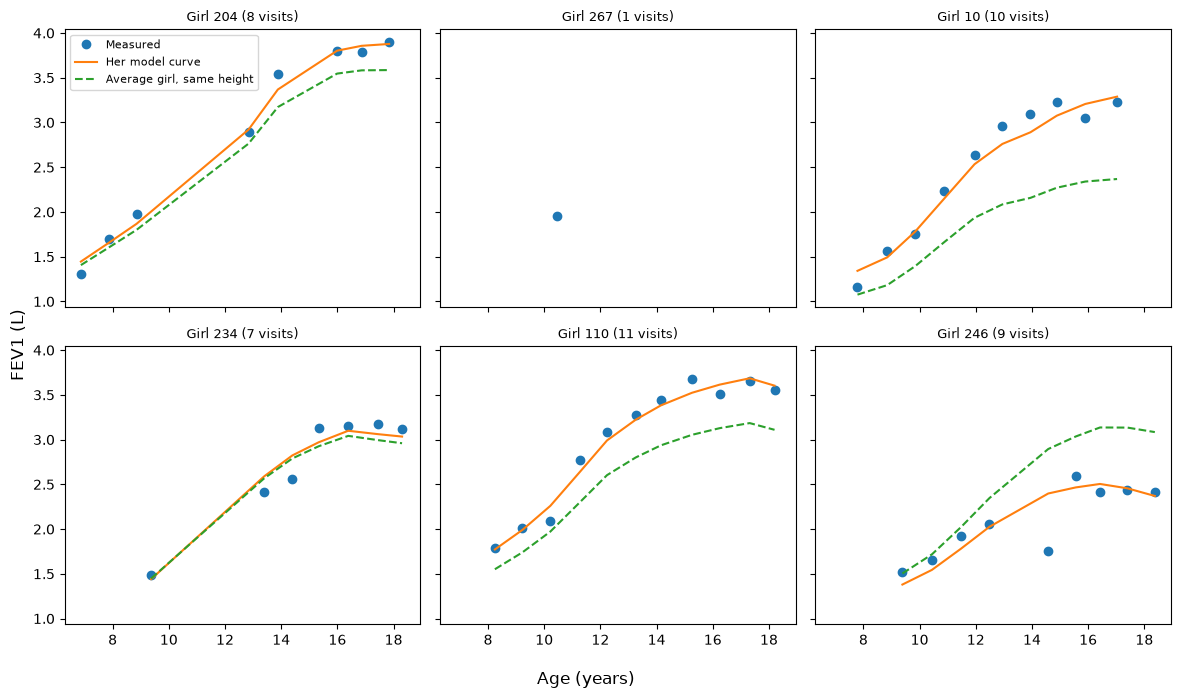

In [11]:
plt.style.use("default")

df["fit_girl"] = np.exp(m3.fittedvalues)   # her personal curve (fixed + random effects)
df["fit_pop"]  = np.exp(m3.predict(df))    # average girl of the same height and age (fixed effects only)

ids = [204, 267, 10, 234, 110, 246]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for ax, cid in zip(axes.flat, ids):
    g = df[df["id"] == cid]
    ax.plot(g["age"], g["fev1"], "o", label="Measured")
    ax.plot(g["age"], g["fit_girl"], "-", label="Her model curve")
    ax.plot(g["age"], g["fit_pop"], "--", label="Average girl, same height")
    ax.set_title(f"Girl {cid} ({len(g)} visits)", fontsize=9)
axes.flat[0].legend(fontsize=8)
fig.supxlabel("Age (years)"); fig.supylabel("FEV1 (L)")
plt.tight_layout(); plt.savefig("../figures/individual_trajectories.png", dpi=150, bbox_inches="tight"); plt.show()

### Check the residuals

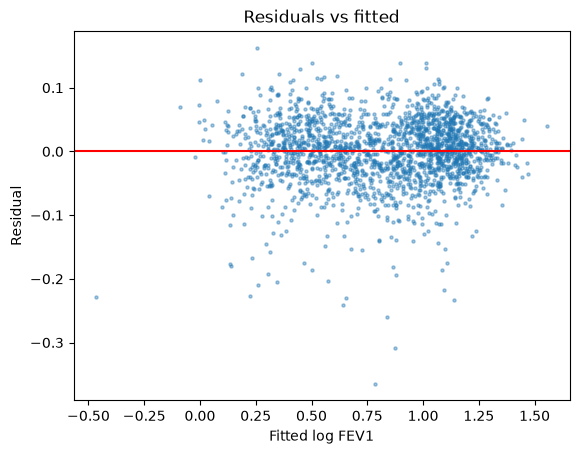

In [12]:
plt.scatter(m3.fittedvalues, m3.resid, s=5, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("Fitted log FEV1"); plt.ylabel("Residual"); plt.title("Residuals vs fitted"); plt.show()

### Sensitivity about the flaggd visits

In [13]:
df_clean = df[~df["suspect"]]
m3_clean = smf.mixedlm("log_fev1 ~ lh_c + bs(age, df=4)", data=df_clean,
                       groups=df_clean["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])
print("lh_c with all data:", round(m3.params["lh_c"], 3), "| without flagged:", round(m3_clean.params["lh_c"], 3))

lh_c with all data: 2.439 | without flagged: 2.363


/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50296/3935907504.py:3: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df_clean["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])


### Summary
- Final model: log FEV1 ~ log height + B-spline(age), random intercept and age slope per girl.
- Random slope (ΔAIC = 65) and spline (ΔAIC = 142) both clearly improved fit.
- ICC = 0.73 (random-intercept model): most unexplained variation is between girls.
- At fixed height, FEV1 increases ~2.3%/year (age), with girls differing in maturation rate.
- Residuals show no systematic pattern; a longer negative tail is consistent with
  effort-dependent spirometry (tests can underestimate but not overestimate capacity).
- Sensitivity: excluding 17 flagged visits changes the height coefficient from 2.44 to 2.36
  (within the 95% CI); conclusions unchanged.